# 03 - Interpretabilidade: o que o modelo aprendeu?

Este notebook responde a duas perguntas de negócio do desafio:
- **Quais fatores mais impactam a alfabetização?**
- **Quais variáveis possuem maior influência nos modelos?**

Técnicas usadas, todas no **teste de 2024**:
1. **Permutation importance**: quanto o AUC cai quando uma feature é embaralhada. Independe do modelo.
2. **SHAP (TreeExplainer)**: contribuição de cada feature para cada previsão, em log-odds.
3. **SHAP agregado por tema**: soma variáveis que medem a mesma coisa (ex.: IDHM, pobreza, Gini),
   para contornar a multicolinearidade vista na EDA.
4. **Explicações locais**: por que o modelo dá risco alto ou baixo a um aluno específico.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from src.config import DIR_MODELOS, SEED
from src.evaluation import interpretabilidade as it
from src.modeling.dados import ALVO, carregar_base_alunos, separar_treino_teste
from src.visualization import graficos as g

g.configurar_estilo()
pd.set_option("display.float_format", "{:.4f}".format)

artefato = joblib.load(DIR_MODELOS / "modelo_aluno_lgbm.joblib")
pipeline = artefato["pipeline"]
colunas = artefato["numericas"] + artefato["categoricas"]

# Mesma base e mesma semente do treino; 20 mil alunos do teste 2024 bastam para estabilizar o SHAP.
_, teste = separar_treino_teste(carregar_base_alunos())
amostra = teste.sample(20_000, random_state=SEED)
X, y = amostra[colunas], amostra[ALVO]

valores_shap, X_transformado = it.calcular_shap(pipeline, X)
nomes = list(X_transformado.columns)
print(f"SHAP calculado para {valores_shap.shape[0]:,} alunos x {valores_shap.shape[1]} colunas transformadas")

SHAP calculado para 20,000 alunos x 120 colunas transformadas


C:\Users\elias.junior\Documents\tech-challenge-fase3\.venv\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


## 1. Permutation importance (independente do modelo)

,queda_auc,desvio
sigla_uf,0.0373,0.0012
tdi_ef_anos_iniciais,0.0065,0.0012
taxa_abandono_ef_anos_iniciais,0.0055,0.0007
pct_populacao_rural_2010,0.0037,0.0005
inse_medio,0.0024,0.0008
taxa_aprovacao_ef_2_ano,0.0013,0.0004
log_populacao,0.0011,0.0003
tamanho_medio_escola,0.0010,0.0003
dsu_ef_anos_iniciais,0.0009,0.0002
pct_laboratorio_informatica,0.0009,0.0001


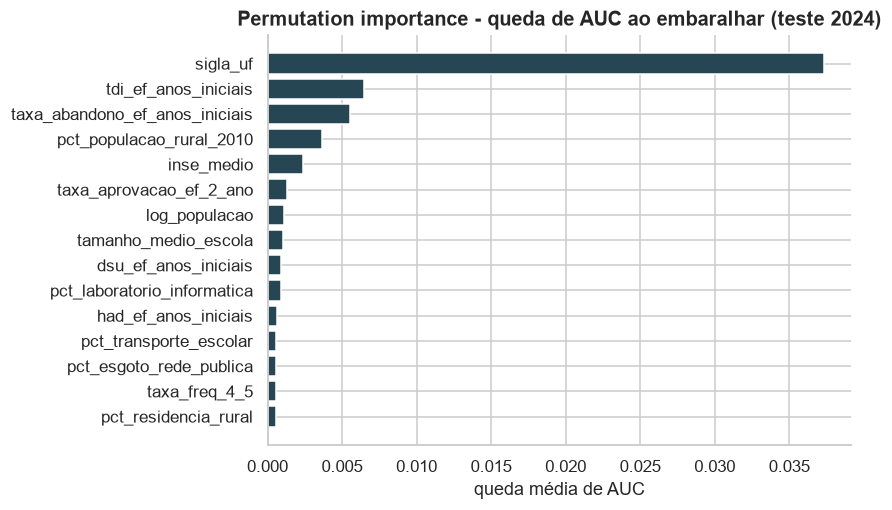

In [2]:
permutacao = it.importancia_permutacao(pipeline, X, y, repeticoes=5)
it.grafico_barras(permutacao["queda_auc"], top=15, salvar="int_01_permutacao",
                  titulo="Permutation importance - queda de AUC ao embaralhar (teste 2024)",
                  xlabel="queda média de AUC");
permutacao.head(15)

**Leitura:**
- Embaralhar a **UF** derruba o AUC em 0,037, de longe a maior queda.
- Em seguida vêm **distorção idade-série** e **abandono** (~0,006 cada), **população rural** e **INSE**.
- As demais quedas são pequenas, mas isso **não** significa que essas variáveis não importam. Como muitas medem o mesmo fenômeno (IDHM, pobreza, Gini, renda), embaralhar uma delas não prejudica o modelo, porque as "irmãs" compensam. É por isso que a leitura por tema, na seção 3, é mais confiável.

## 2. SHAP - visão global

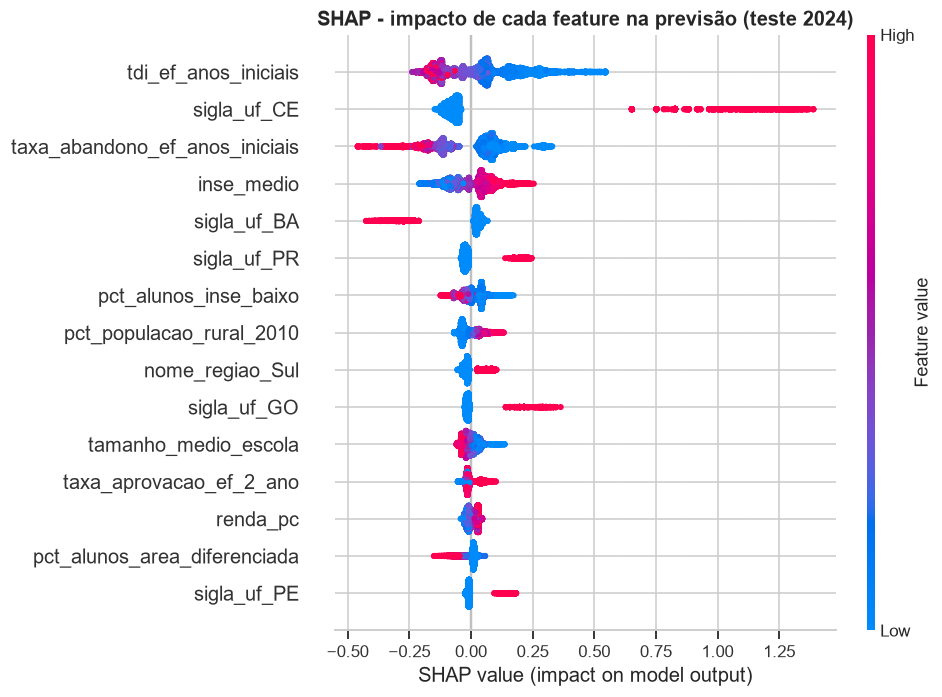

In [3]:
it.grafico_beeswarm(valores_shap, X_transformado, salvar="int_02_shap_beeswarm");

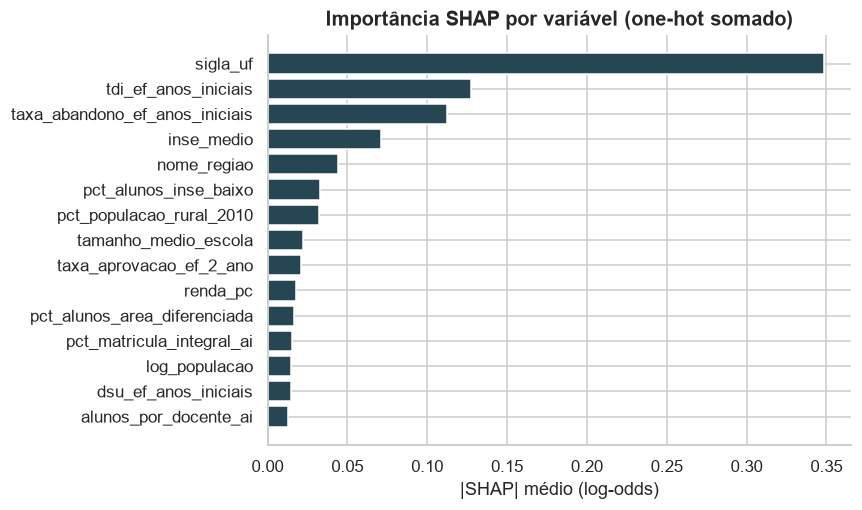

In [4]:
por_feature = it.importancia_por_feature(valores_shap, nomes)
it.grafico_barras(por_feature, top=15, salvar="int_03_shap_por_feature",
                  titulo="Importância SHAP por variável (one-hot somado)", xlabel="|SHAP| médio (log-odds)");

**Leitura do beeswarm** (cada ponto é um aluno; vermelho = valor alto da feature):
- **Distorção idade-série:** valores baixos (azul) empurram fortemente para "alfabetizado" e valores altos (vermelho) para o risco.
- **Abandono:** mesmo padrão; mais abandono significa mais risco.
- **INSE:** nível socioeconômico mais alto aumenta a chance.
- **UF:** estar no Ceará soma até +1,4 em log-odds, o maior efeito isolado do modelo. Bahia, Sergipe e Rio Grande do Norte puxam para baixo; Paraná, Goiás e Pernambuco puxam para cima.
- **Áreas diferenciadas:** redes com mais alunos em áreas indígenas, quilombolas ou de assentamento têm risco maior.

## 3. Quais fatores mais impactam? Importância por tema

,% da importância total
Trajetória escolar,30.8000
Estado (UF) e região,29.5000
Nível socioeconômico,19.0000
Porte da rede e do município,6.0000
Ruralidade e diversidade,5.9000
Infraestrutura escolar,4.8000
Docentes e equipe,3.7000
Rede (estadual/municipal),0.4000


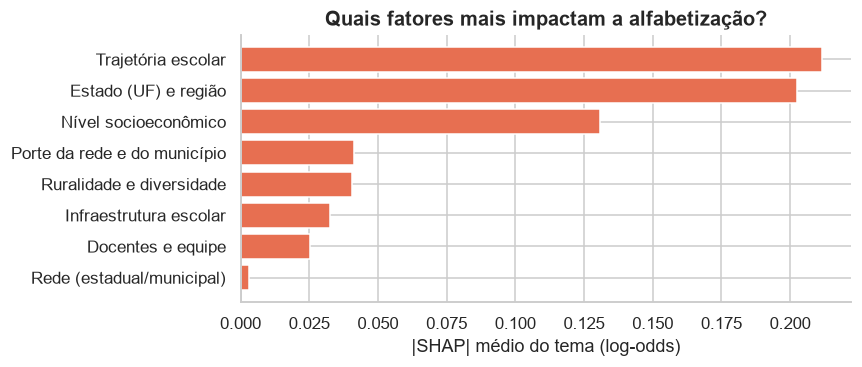

In [5]:
por_tema = it.importancia_por_tema(valores_shap, nomes)
it.grafico_barras(por_tema, salvar="int_04_shap_por_tema", cor="#e76f51",
                  titulo="Quais fatores mais impactam a alfabetização?", xlabel="|SHAP| médio do tema (log-odds)");
(por_tema / por_tema.sum()).mul(100).round(1).to_frame("% da importância total")

**Resposta - quais fatores mais impactam a alfabetização?**

1. **Trajetória escolar (31%)**: distorção idade-série, abandono e aprovação. Redes onde as crianças já atrasam ou abandonam nos anos iniciais são as que menos alfabetizam. É o fator mais **acionável**: acompanhamento de frequência e recomposição de aprendizagem.
2. **Estado e região (30%)**: o efeito da política e da gestão estadual, detalhado na seção 4.
3. **Nível socioeconômico (19%)**: INSE, pobreza infantil, renda, IDHM. Importa, mas **não é destino**: pesa menos que a trajetória escolar e que o estado.
4. **Porte, ruralidade e diversidade (12% somados)**: redes grandes, rurais e de áreas diferenciadas têm desafios específicos.
5. **Infraestrutura (5%) e docentes (4%)**: têm efeito no nível agregado, mas pequeno depois de considerados os fatores anteriores. Nos dados públicos, porém, a qualidade da prática pedagógica não é medida, só a formação formal dos docentes.

## 4. O efeito do estado: política educacional além do contexto

A contribuição SHAP da UF mede o que o modelo atribui ao estado **depois de considerar** trajetória
escolar, nível socioeconômico, infraestrutura e ruralidade. Valores positivos indicam estados que
alfabetizam **mais do que o contexto deles faria esperar**.

,efeito SHAP da UF,taxa real 2024 (%)
sigla_uf,,
SE,-0.6900,42.5400
RN,-0.5100,37.0900
TO,-0.4900,50.5800
BA,-0.4000,37.4700
SC,-0.2400,65.4100
AL,-0.2300,46.1500
MT,-0.1900,62.7600
MS,-0.1800,56.7900
MG,-0.1300,73.2500


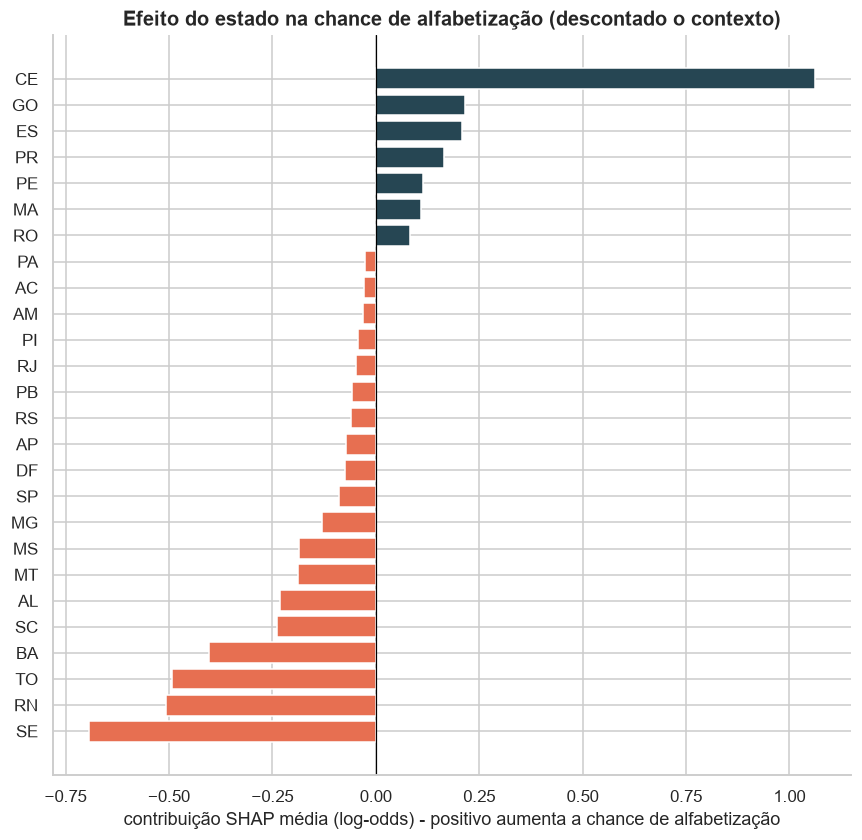

In [6]:
efeito_uf = it.efeito_por_categoria(valores_shap, nomes, X, "sigla_uf")
it.grafico_efeito_categoria(efeito_uf, titulo="Efeito do estado na chance de alfabetização (descontado o contexto)",
                            salvar="int_05_efeito_uf");

taxa_real = amostra.groupby("sigla_uf")[ALVO].mean().mul(100)
pd.DataFrame({"efeito SHAP da UF": efeito_uf, "taxa real 2024 (%)": taxa_real}).sort_values("efeito SHAP da UF").round(2)

**Leitura - o achado mais relevante para política pública:**
- **Ceará (+1,06):** alfabetiza muito acima do que seu contexto socioeconômico faria esperar, com 85% de taxa real. É o efeito associado ao **PAIC/MAIS PAIC**, o regime de colaboração Estado-municípios com avaliação, material estruturado e incentivo via ICMS, há quase 20 anos.
- **Goiás, Espírito Santo, Paraná e Pernambuco:** também entregam mais do que o contexto prevê. Vale investigar quais políticas estaduais de alfabetização explicam esse resultado.
- **Sergipe, Rio Grande do Norte, Tocantins e Bahia:** entregam **menos** do que o contexto prevê. É aqui que mudanças de gestão têm maior potencial.
- **Minas Gerais (-0,13):** apesar da taxa alta (73%), tem efeito ligeiramente negativo. O resultado alto é explicado pelo bom contexto, não por um "plus" de gestão. Isso mostra por que o SHAP é mais informativo que a taxa crua.

O efeito de UF é **associação, não causalidade**: ele captura tudo o que é comum ao estado e não está nas features. Ainda assim, a convergência com a literatura sobre o PAIC é forte.

## 5. Como cada fator age? Gráficos de dependência

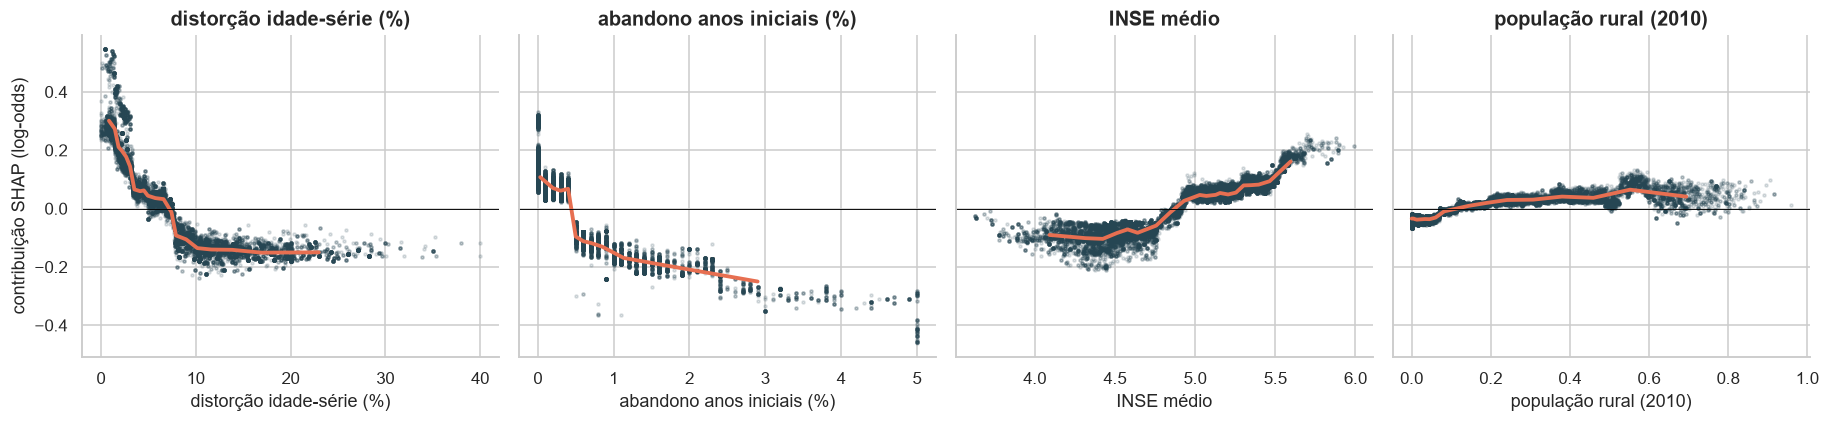

In [7]:
rotulos = {
    "tdi_ef_anos_iniciais": "distorção idade-série (%)",
    "taxa_abandono_ef_anos_iniciais": "abandono anos iniciais (%)",
    "inse_medio": "INSE médio",
    "pct_populacao_rural_2010": "população rural (2010)",
}
X_plot = X_transformado.copy()
X_plot["taxa_abandono_ef_anos_iniciais"] = X_plot["taxa_abandono_ef_anos_iniciais"].clip(upper=5)
X_plot["tdi_ef_anos_iniciais"] = X_plot["tdi_ef_anos_iniciais"].clip(upper=40)
it.grafico_dependencia(valores_shap, X_plot, list(rotulos), rotulos, salvar="int_06_dependencia");

**Leitura - os efeitos têm limiares, não são lineares:**
- **Distorção idade-série:** o efeito positivo é forte até ~5% e fica negativo acima de ~8%. Depois disso **satura**: ter 10% ou 30% de distorção pesa praticamente igual. Ou seja, o ganho está em manter a distorção muito baixa.
- **Abandono:** qualquer abandono acima de ~0,5% já muda o sinal, e a piora continua aos poucos. Abandono zero é um forte marcador de rede organizada.
- **INSE:** há um **degrau por volta de 4,8**. Abaixo dele o efeito é negativo e estável; acima, cresce de forma contínua.
- **População rural:** o efeito é pequeno e levemente positivo, depois de considerar as outras variáveis rurais (% de alunos em escola rural, transporte). É um efeito **condicional**, que não deve ser lido isoladamente.

Esses limiares justificam o uso de um modelo de árvores: a regressão logística só representa efeitos lineares.

## 6. Consistência com o baseline: coeficientes da regressão logística

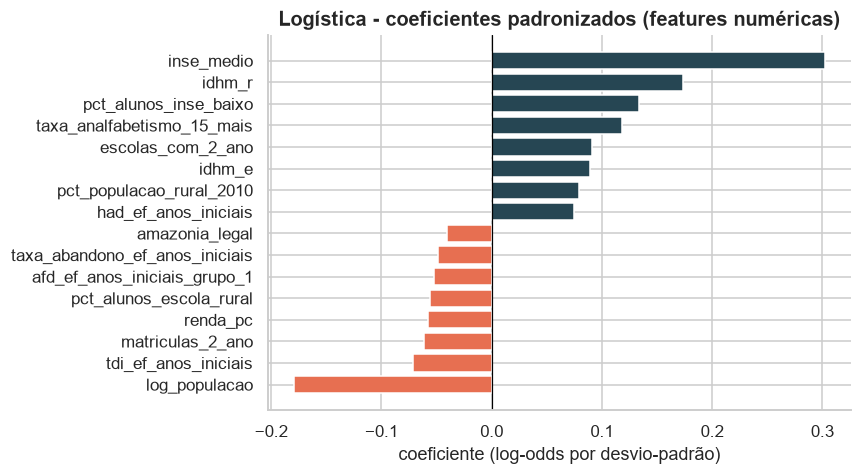

In [8]:
logistica = joblib.load(DIR_MODELOS / "modelo_aluno_logistica.joblib")
coeficientes = pd.Series(logistica.named_steps["modelo"].coef_[0],
                         index=logistica.named_steps["prep"].get_feature_names_out())
coeficientes = coeficientes[[not n.startswith(("missingindicator_", "sigla_uf_", "nome_regiao_", "rede_nome_")) for n in coeficientes.index]]
destaque = pd.concat([coeficientes.nsmallest(8), coeficientes.nlargest(8)])
g.correlacoes_com_alvo(destaque, salvar="int_07_coef_logistica",
                       titulo="Logística - coeficientes padronizados (features numéricas)",
                       xlabel="coeficiente (log-odds por desvio-padrão)");

**Leitura - por que os coeficientes da logística não servem para interpretar este problema:**
- **Onde concorda com o SHAP:** INSE positivo; população total, distorção, abandono e escola rural negativos.
- **Onde se contradiz:** alguns sinais **contrariam a intuição**, como `pct_alunos_inse_baixo` e `taxa_analfabetismo_15_mais` positivos e `renda_pc` negativo. É o efeito da **multicolinearidade**: com variáveis socioeconômicas quase redundantes, o modelo linear distribui o peso entre elas de forma instável, e uma vira "correção" da outra.
- **Por que usar o SHAP:** na leitura agregada por tema, esses efeitos se compensam. É mais um motivo para basear as conclusões no SHAP por tema e não em coeficientes isolados.

## 7. Explicações locais: por que este aluno tem risco alto?

maior risco: SE | rede municipal | município 2804805 | P(alfabetizado) = 23.8% | real = não alfabetizado
menor risco: CE | rede municipal | município 2304236 | P(alfabetizado) = 94.7% | real = alfabetizado


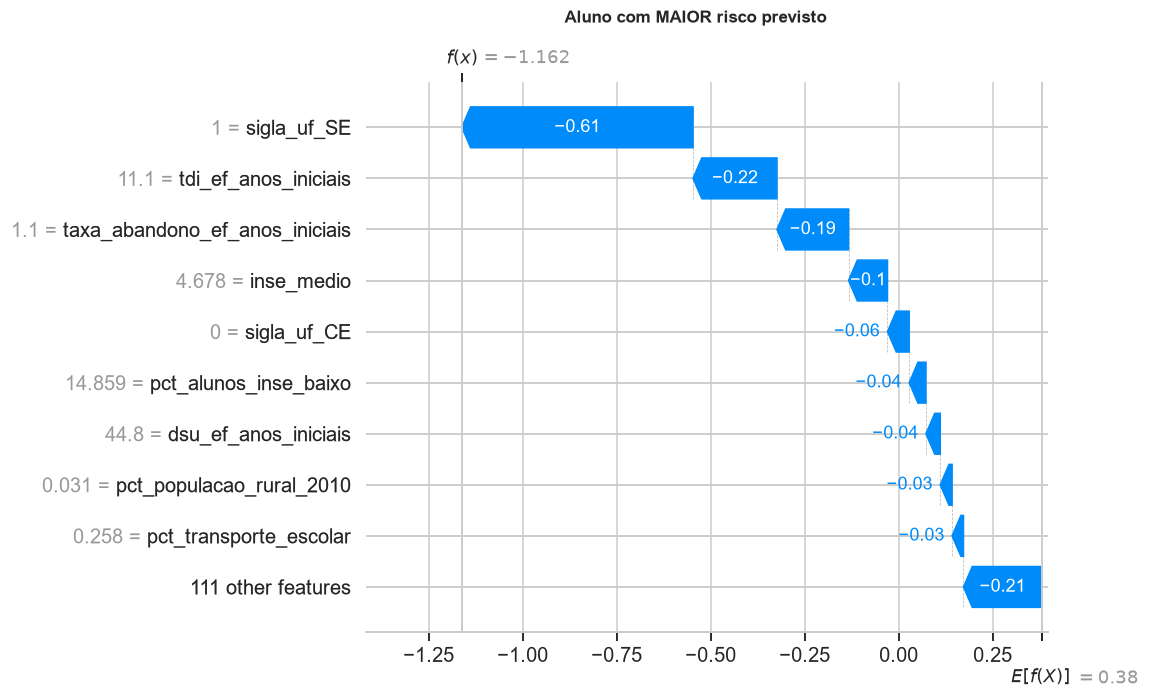

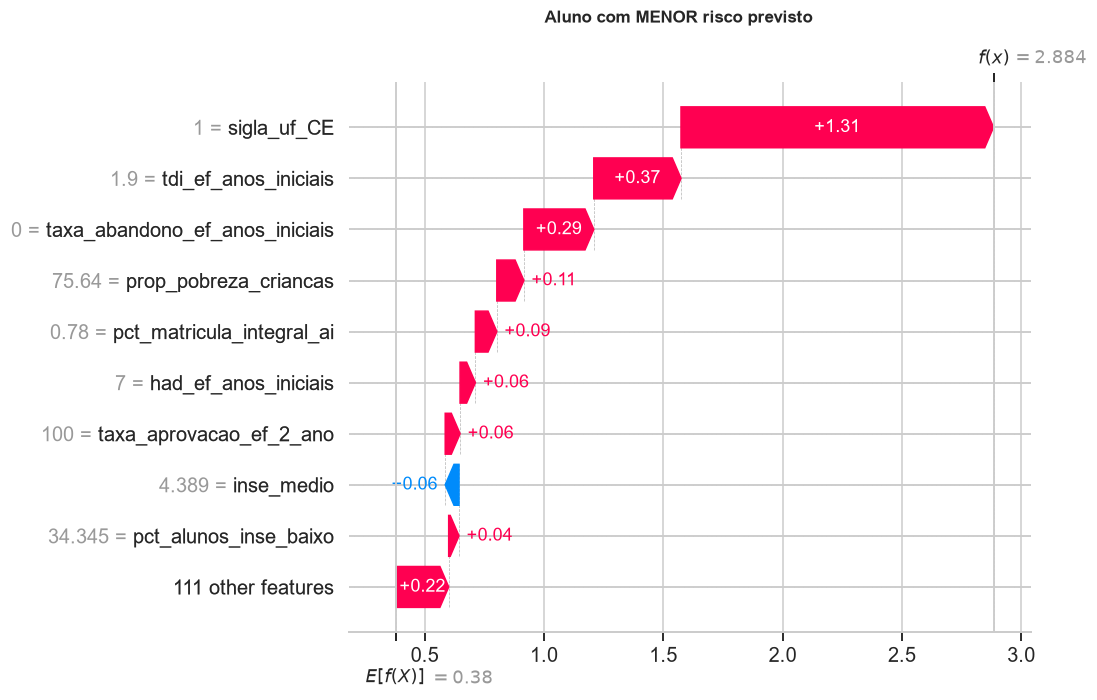

In [9]:
proba = pipeline.predict_proba(X)[:, 1]
explainer = shap.TreeExplainer(pipeline.named_steps["modelo"])
base = float(np.ravel(explainer.expected_value)[-1])

def explicar(posicao, titulo, salvar):
    explicacao = shap.Explanation(values=valores_shap[posicao], base_values=base,
                                  data=X_transformado.iloc[posicao].values, feature_names=nomes)
    plt.figure()
    shap.plots.waterfall(explicacao, max_display=10, show=False)
    fig = plt.gcf()
    fig.suptitle(titulo, fontweight="bold", fontsize=11)
    fig.savefig(g.DIR_IMAGENS / f"{salvar}.png", bbox_inches="tight")
    plt.show()

maior_risco, menor_risco = int(np.argmin(proba)), int(np.argmax(proba))
for nome, pos in [("maior risco", maior_risco), ("menor risco", menor_risco)]:
    linha = amostra.iloc[pos]
    print(f"{nome}: {linha['sigla_uf']} | rede {linha['rede_nome']} | município {linha['id_municipio']} | "
          f"P(alfabetizado) = {proba[pos]:.1%} | real = {'alfabetizado' if linha[ALVO] else 'não alfabetizado'}")

explicar(maior_risco, "Aluno com MAIOR risco previsto", "int_08_local_maior_risco")
explicar(menor_risco, "Aluno com MENOR risco previsto", "int_09_local_menor_risco")

**Leitura das explicações locais:**

- **Maior risco:** uma criança da rede municipal de um município de **Sergipe**. A chance prevista de alfabetização é 24%, e o real foi não alfabetizada. Os motivos são, em ordem: o efeito do estado (-0,61), distorção idade-série de 11% (-0,22), abandono de 1,1% (-0,19) e INSE abaixo do limiar (-0,10).
- **Menor risco:** uma criança da rede municipal de um município do **Ceará**. A chance prevista é de 95%, e ela foi alfabetizada.

O segundo caso é o que melhor resume o projeto. Esse município cearense tem **76% das crianças em situação de pobreza** e INSE baixo (4,39), mas a rede tem distorção idade-série de só 1,9%, **abandono zero**, aprovação de 100% e 78% das matrículas em tempo integral. Somados ao efeito do estado (+1,31), esses fatores superam com folga a desvantagem socioeconômica.

Na prática, um gestor pode ver **por que** cada rede foi sinalizada e escolher a alavanca: fluxo escolar, tempo integral ou gestão estadual.

## 8. Respostas às perguntas de negócio

**Quais fatores mais impactam a alfabetização?**
Nesta ordem: **trajetória escolar** (31%: distorção idade-série e abandono), **estado/política estadual** (30%), **nível socioeconômico** (19%) e, com peso menor, **porte, ruralidade e diversidade**, **infraestrutura** e **formação docente**.

**Quais variáveis possuem maior influência no modelo?**
`sigla_uf`, com destaque para o Ceará, `tdi_ef_anos_iniciais`, `taxa_abandono_ef_anos_iniciais`, `inse_medio` e `pct_alunos_inse_baixo`. A permutation importance, independente do modelo, confirma o mesmo ranking no topo.

**Mensagem para o gestor:** contexto socioeconômico importa, mas **não determina** o resultado. Estados com política estruturada de alfabetização (CE, GO, ES, PR, PE) entregam bem mais do que seu contexto prevê. E as alavancas com maior efeito, fluxo escolar e regime de colaboração, estão **ao alcance da gestão pública**.